# B2 — UAE E-Commerce Fraud Intelligence
## Memory-Optimized Data Science & Machine Learning (8 GB RAM Edition)

**Purpose:** Rebuild the original UAE E-Commerce Fraud Intelligence notebook with safer memory usage, leakage-aware feature selection, chronological train/validation/test splits, and threshold selection that does not use the final test set.

**Dataset expected:** `uae_ecom_fraud_100k.csv` (or matching `.parquet` / `.xlsx` file).

### Engineering principles

- Keep sparse matrices sparse. Never call `.toarray()` on the full one-hot encoded dataset.
- Use `float32` where practical.
- Cap high-cardinality categorical features.
- Exclude identifiers and suspicious/post-event fraud flags from predictors unless point-in-time availability is independently established.
- Use chronological train/validation/test splits when timestamps are usable.
- Select models and thresholds on validation data. Use the test set once for final evaluation.
- Treat fraud labels, clusters, and anomalies according to their actual meaning. An anomaly is not automatically fraud.
- Keep optional, memory-heavy work separate and sampled.

> **Data note:** The original notebook's recorded dataset source was `synthetic:ecom-fraud-uae-v1`. Treat results as a learning/portfolio exercise, not evidence of real-world UAE fraud prevalence or live payment performance.

## 0. Laptop and memory strategy

This notebook is designed for an 8 GB RAM machine. Close unnecessary applications before running it.

**Recommended environment**
- Python 3.10–3.12
- Jupyter Notebook / JupyterLab
- 8 GB system RAM
- CPU execution is supported; a dedicated GPU is not required for the main workflow.

Install packages from a notebook cell if needed. Install PyTorch only if you intend to try the optional neural-network exercise.

In [1]:
%pip install -U pandas numpy matplotlib seaborn scikit-learn scipy joblib statsmodels psutil
# Optional:
# %pip install -U xgboost
# %pip install -U torch
# %pip install -U streamlit plotly

  Using cached pandas-3.1.1-cp313-cp313-win_amd64.whl.metadata (16 kB)
  Using cached numpy-2.5.4-cp313-cp313-win_amd64.whl.metadata (6.6 kB)
Using cached pandas-3.1.1-cp313-cp313-win_amd64.whl (10.7 MB)
Using cached numpy-2.5.4-cp313-cp313-win_amd64.whl (12.6 MB)
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.2 MB 1.9 MB/s eta 0:00:05
   --- ------------------------------------ 0.8/8.2 MB 2.1 MB/s eta 0:00:04
   --- ------------------------------------ 0.8/8.2 MB 2.1 MB/s eta 0:00:04
   --- ------------------------------------ 0.8/8.2 MB 2.1 MB/s eta 0:00:04
   --- ------------------------------------ 0.8/8.2 MB 2.1 MB/s eta 0:00:04
   --- ------------------------------------ 0.8/8.2 MB 2.1 MB/s eta 0:00:04
   --- ------------------------------------ 0.8/8.2 MB 2.1 MB/s eta 0:00

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("MKL_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")

import gc
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import sparse
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest, HistGradientBoostingClassifier
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report, precision_recall_curve,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split
import joblib

warnings.filterwarnings("default")

try:
    import psutil
    print(f"System RAM: {psutil.virtual_memory().total / 1024**3:.2f} GB")
    print(f"Available RAM: {psutil.virtual_memory().available / 1024**3:.2f} GB")
except ImportError:
    print("Install psutil to display RAM usage.")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

System RAM: 7.88 GB
Available RAM: 0.68 GB
Pandas: 3.1.1
NumPy: 2.5.4


## 1. Load the dataset safely

Place the dataset in the same folder as this notebook, or update `DATA_PATH` below.

For CSV, `low_memory=False` improves type inference. The notebook loads the dataset into a DataFrame, so 8 GB RAM is still a practical limit. Avoid loading several copies of the full DataFrame.

In [3]:
FILE_STEM = "uae_ecom_fraud_100k"
DATA_PATH = None  # Example: Path(r"C:\Users\YourName\Documents\project\uae_ecom_fraud_100k.csv")

if DATA_PATH is not None:
    path = Path(DATA_PATH)
else:
    candidates = []
    for ext in (".csv", ".parquet", ".xlsx", ".xls"):
        candidates.extend(Path.cwd().glob(FILE_STEM + ext))
    if not candidates:
        for ext in (".csv", ".parquet", ".xlsx", ".xls"):
            candidates.extend(Path.cwd().glob("**/" + FILE_STEM + ext))
    if not candidates:
        raise FileNotFoundError(
            "Dataset not found. Put uae_ecom_fraud_100k.csv beside this notebook "
            "or set DATA_PATH to its full path."
        )
    path = candidates[0]

if path.suffix.lower() == ".csv":
    df = pd.read_csv(path, low_memory=False)
elif path.suffix.lower() == ".parquet":
    df = pd.read_parquet(path)
elif path.suffix.lower() in (".xlsx", ".xls"):
    df = pd.read_excel(path)
else:
    raise ValueError(f"Unsupported file format: {path.suffix}")

df.columns = df.columns.astype(str).str.strip()
print("Loaded:", path.name)
print("Shape:", df.shape)
display(df.head(5))

Loaded: uae_ecom_fraud_100k.csv
Shape: (100000, 36)


,transaction_id,user_id,timestamp_utc,amount_aed,currency,payment_method,device_type,browser,merchant_category,items_count,...,local_hour,odd_hour,is_fraud,fraud_flag_ip,fraud_flag_mismatch,fraud_flag_velocity,fraud_flag_new_account,fraud_flag_prev_cb,fraud_flag_odd_hour,data_source
0,500086758,1000466,2024-01-01T00:02:03Z,71.47,AED,card,desktop,Chrome,Pharmacy,3,...,4,1,0,0,0,0,0,0,1,synthetic:ecom-fraud-uae-v1
1,500060464,1002828,2024-01-01T00:03:11Z,70.25,AED,card,mobile,Chrome,Groceries,1,...,4,1,0,0,0,0,1,0,1,synthetic:ecom-fraud-uae-v1
2,500039909,1010349,2024-01-01T00:04:10Z,116.25,AED,bank_transfer,desktop,Chrome,Beauty,2,...,4,1,0,0,0,0,0,0,1,synthetic:ecom-fraud-uae-v1
3,500074412,1015360,2024-01-01T00:05:14Z,99.41,AED,apple_pay,mobile,Safari,Toys,2,...,4,1,0,0,0,0,0,0,1,synthetic:ecom-fraud-uae-v1
4,500038110,1022253,2024-01-01T00:11:03Z,529.40,AED,card,desktop,Safari,Travel,2,...,4,1,0,0,0,0,1,1,1,synthetic:ecom-fraud-uae-v1


## 2. Identify key columns and validate the target

The notebook searches common names for timestamp, transaction amount, fraud target, and transaction ID. Confirm the detected fields before proceeding.

In [4]:
def find_column(frame, candidates):
    lookup = {str(c).strip().lower(): c for c in frame.columns}
    return next((lookup[name.lower()] for name in candidates if name.lower() in lookup), None)

DATE = find_column(df, ["timestamp_utc", "timestamp", "transaction_date", "date", "created_at"])
AMOUNT = find_column(df, ["amount_aed", "transaction_amount", "amount", "sales", "gtv"])
TARGET = find_column(df, ["is_fraud", "fraud", "fraud_label"])
ID = find_column(df, ["transaction_id", "order_id", "id"])

print({"date": DATE, "amount": AMOUNT, "target": TARGET, "id": ID})
if TARGET is None:
    raise ValueError("Fraud target not found. Expected is_fraud, fraud, or fraud_label.")

data = df.copy()
if DATE:
    data[DATE] = pd.to_datetime(data[DATE], errors="coerce", utc=True)
if AMOUNT:
    data[AMOUNT] = pd.to_numeric(data[AMOUNT], errors="coerce")

if pd.api.types.is_numeric_dtype(data[TARGET]):
    target_numeric = pd.to_numeric(data[TARGET], errors="coerce")
else:
    label_map = {
        "1": 1, "true": 1, "yes": 1, "fraud": 1,
        "0": 0, "false": 0, "no": 0, "legitimate": 0, "non-fraud": 0
    }
    target_numeric = data[TARGET].astype(str).str.strip().str.lower().map(label_map)

valid_target = target_numeric.isin([0, 1])
data = data.loc[valid_target].copy()
y = target_numeric.loc[valid_target].astype("int8").reset_index(drop=True)
data = data.reset_index(drop=True)

if AMOUNT:
    data[AMOUNT] = pd.to_numeric(data[AMOUNT], errors="coerce")
    valid_amount = data[AMOUNT].isna() | (data[AMOUNT] >= 0)
    data = data.loc[valid_amount].reset_index(drop=True)
    y = y.loc[valid_amount].reset_index(drop=True)

print("Rows retained:", len(data))
print("Target counts:")
display(y.value_counts().rename(index={0: "non-fraud", 1: "fraud"}).to_frame("transactions"))
print(f"Fraud prevalence: {y.mean() * 100:.3f}%")
if y.nunique() != 2:
    raise ValueError("Both target classes (0 and 1) must be present.")

{'date': 'timestamp_utc', 'amount': 'amount_aed', 'target': 'is_fraud', 'id': 'transaction_id'}
Rows retained: 100000
Target counts:


,transactions
is_fraud,
non-fraud,91789
fraud,8211


Fraud prevalence: 8.211%


## 3. Exploratory data analysis (EDA)

Start with compact summaries. Do not print the entire dataset or create large intermediate copies.

In [5]:
print("Dataset shape:", data.shape)
display(data.dtypes.astype(str).to_frame("dtype"))
display(
    pd.DataFrame({
        "missing_count": data.isna().sum(),
        "missing_pct": (data.isna().mean() * 100).round(2),
        "unique_values": data.nunique(dropna=True)
    }).sort_values("missing_pct", ascending=False).head(25)
)

print("Duplicate rows:", int(data.duplicated().sum()))
print("Fraud class balance:")
display(y.value_counts(normalize=True).rename("share").to_frame())

Dataset shape: (100000, 36)


,dtype
transaction_id,int64
user_id,int64
timestamp_utc,"datetime64[us, UTC]"
amount_aed,float64
currency,str
payment_method,str
device_type,str
browser,str
merchant_category,str
items_count,int64


,missing_count,missing_pct,unique_values
transaction_id,0,0.0,100000
user_id,0,0.0,28937
timestamp_utc,0,0.0,99839
amount_aed,0,0.0,33713
currency,0,0.0,1
payment_method,0,0.0,5
device_type,0,0.0,3
browser,0,0.0,6
merchant_category,0,0.0,10
items_count,0,0.0,9


Duplicate rows: 0
Fraud class balance:


,share
is_fraud,
0,0.91789
1,0.08211


,transactions,total_amount,mean_amount,median_amount
_target,,,,
0,91789,14658058.92,159.692980,82.11
1,8211,1628333.28,198.311202,81.95


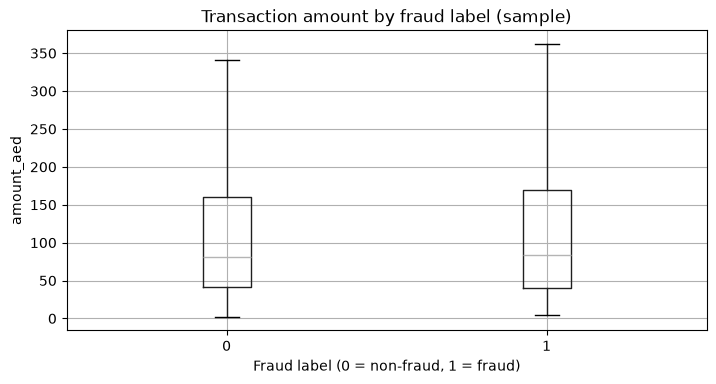

In [6]:
if AMOUNT:
    amount_summary = data.assign(_target=y).groupby("_target")[AMOUNT].agg(
        transactions="count", total_amount="sum", mean_amount="mean", median_amount="median"
    )
    display(amount_summary)
    sample = data[[AMOUNT]].copy()
    sample["_target"] = y.values
    sample = sample.sample(min(15000, len(sample)), random_state=42)
    sample.boxplot(column=AMOUNT, by="_target", figsize=(8, 4), showfliers=False)
    plt.title("Transaction amount by fraud label (sample)")
    plt.suptitle("")
    plt.xlabel("Fraud label (0 = non-fraud, 1 = fraud)")
    plt.ylabel(AMOUNT)
    plt.show()

## 4. Leakage review and feature policy

The target is `is_fraud` (or its detected equivalent). Identifiers are excluded. The following fields are quarantined by default because they may encode a post-event decision, a precomputed fraud score, or a fraud rule. Do not reintroduce them unless you can prove they are available at the exact prediction timestamp.

Potentially suspicious patterns include:
- `fraud_flag*`
- `fraud_score`
- `chargeback*`
- `is_high_risk`
- `transactions_last_*` (must be verified as point-in-time features)
- fields explicitly describing investigation outcomes or later payment disputes

This is a conservative starting policy, not a substitute for a data dictionary and domain review.

In [7]:
exclude_columns = {TARGET}
if ID:
    exclude_columns.add(ID)

# Timestamps are used to order the split, not as raw predictors.
if DATE:
    exclude_columns.add(DATE)

risk_terms = [
    "chargeback", "is_high_risk", "fraud_score", "fraud_flag",
    "transactions_last_1h", "transactions_last_24h",
    "investigation", "dispute_outcome", "review_result"
]
quarantined_columns = [
    c for c in data.columns
    if any(term in str(c).lower() for term in risk_terms)
]
exclude_columns.update(quarantined_columns)

# Additional identifier-like columns: high-cardinality IDs are not useful
# by default and can cause huge one-hot matrices or leakage.
identifier_like = []
for c in data.columns:
    if c in exclude_columns:
        continue
    name = str(c).lower()
    if name.endswith("_id") or name in {"ip_address", "email", "phone", "device_id"}:
        identifier_like.append(c)
exclude_columns.update(identifier_like)

candidate_features = data.drop(columns=list(exclude_columns), errors="ignore").copy()
candidate_features = candidate_features.dropna(axis=1, how="all")

# Remove constant columns.
candidate_features = candidate_features.loc[
    :, candidate_features.nunique(dropna=True) > 1
]

# Remove datetime predictors unless separately engineered using only past data.
datetime_columns = [
    c for c in candidate_features.columns
    if pd.api.types.is_datetime64_any_dtype(candidate_features[c])
]
candidate_features = candidate_features.drop(columns=datetime_columns)

print("Excluded:", sorted(map(str, exclude_columns)))
print("Quarantined fraud/post-event fields:", quarantined_columns)
print("Identifier-like fields:", identifier_like)
print("Candidate feature count:", candidate_features.shape[1])
display(candidate_features.head(3))

Excluded: ['fraud_flag_ip', 'fraud_flag_mismatch', 'fraud_flag_new_account', 'fraud_flag_odd_hour', 'fraud_flag_prev_cb', 'fraud_flag_velocity', 'ip_address', 'is_fraud', 'timestamp_utc', 'transaction_id', 'transactions_last_1h', 'transactions_last_24h', 'user_id', 'user_is_high_risk', 'user_prev_chargebacks']
Quarantined fraud/post-event fields: ['user_prev_chargebacks', 'user_is_high_risk', 'transactions_last_24h', 'transactions_last_1h', 'fraud_flag_ip', 'fraud_flag_mismatch', 'fraud_flag_velocity', 'fraud_flag_new_account', 'fraud_flag_prev_cb', 'fraud_flag_odd_hour']
Identifier-like fields: ['user_id', 'ip_address']
Candidate feature count: 19


,amount_aed,payment_method,device_type,browser,merchant_category,items_count,avg_item_price,shipping_city,billing_city,shipping_billing_match,ip_risk_score,card_present,bin_country,card_age_days,card_country_match,email_domain,user_account_age_days,local_hour,odd_hour
0,71.47,card,desktop,Chrome,Pharmacy,3,23.82,Dubai,Dubai,1,35.3,0,AE,85,1,gmail.com,365,4,1
1,70.25,card,mobile,Chrome,Groceries,1,70.25,Abu Dhabi,Abu Dhabi,1,30.2,0,SA,123,0,outlook.com,-192,4,1
2,116.25,bank_transfer,desktop,Chrome,Beauty,2,58.12,Cairo,Cairo,1,32.7,0,PK,542,0,gmail.com,1744,4,1


## 5. Build a leakage-aware chronological train / validation / test split

The split is 70% training, 15% validation, and 15% final test, ordered by timestamp. If no usable timestamp exists, a stratified random split is used and clearly labelled.

- Training: fit preprocessing and model parameters.
- Validation: compare models and select the operating threshold.
- Test: final evaluation of the selected model and threshold. Do not tune on this set.

In [8]:
if DATE and data[DATE].notna().mean() >= 0.90:
    order = data[DATE].sort_values(kind="stable").index.to_numpy()
    n = len(order)
    i_train = int(n * 0.70)
    i_valid = int(n * 0.85)
    train_idx = order[:i_train]
    valid_idx = order[i_train:i_valid]
    test_idx = order[i_valid:]
    split_strategy = "Chronological 70/15/15"
else:
    all_idx = np.arange(len(data))
    train_idx, temp_idx = train_test_split(
        all_idx, test_size=0.30, random_state=42, stratify=y
    )
    valid_idx, test_idx = train_test_split(
        temp_idx, test_size=0.50, random_state=42, stratify=y.iloc[temp_idx]
    )
    split_strategy = "Stratified random 70/15/15 (timestamp unavailable/unreliable)"

X_train = candidate_features.iloc[train_idx].copy()
X_valid = candidate_features.iloc[valid_idx].copy()
X_test = candidate_features.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_valid = y.iloc[valid_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Split:", split_strategy)
for label, target_part in [("Train", y_train), ("Validation", y_valid), ("Test", y_test)]:
    print(label, "rows:", len(target_part), "| fraud rate:", round(target_part.mean() * 100, 3), "%")
    if target_part.nunique() < 2:
        raise ValueError(f"{label} split contains only one class. Review timestamp distribution.")

Split: Chronological 70/15/15
Train rows: 70000 | fraud rate: 8.193 %
Validation rows: 15000 | fraud rate: 8.22 %
Test rows: 15000 | fraud rate: 8.287 %


## 6. Memory-efficient preprocessing

Important safeguards:
- `OneHotEncoder` returns a sparse matrix.
- `min_frequency` groups rare categories.
- `max_categories` caps the number of categories per feature when supported.
- Numeric scaling uses `with_mean=False`, which is compatible with sparse combined output.
- The combined matrix is kept sparse; do not convert it to a dense NumPy array.

The preprocessing pipeline is fitted on training data only.

In [9]:
numeric_columns = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_columns = X_train.select_dtypes(exclude=["number", "bool"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler(with_mean=False))
])

# Compatibility with older scikit-learn versions.
try:
    categorical_encoder = OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20,
        max_categories=50,
        sparse_output=True,
        dtype=np.float32
    )
except TypeError:
    categorical_encoder = OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20,
        max_categories=50,
        sparse=True,
        dtype=np.float32
    )

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", categorical_encoder)
])

transformers = []
if numeric_columns:
    transformers.append(("num", numeric_pipeline, numeric_columns))
if categorical_columns:
    transformers.append(("cat", categorical_pipeline, categorical_columns))

if not transformers:
    raise ValueError("No usable numeric or categorical predictor columns remain.")

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop",
    sparse_threshold=1.0
)

X_train_matrix = preprocessor.fit_transform(X_train)
X_valid_matrix = preprocessor.transform(X_valid)
X_test_matrix = preprocessor.transform(X_test)

def matrix_report(name, matrix):
    shape = matrix.shape
    if sparse.issparse(matrix):
        mb = matrix.data.nbytes / (1024**2) + matrix.indices.nbytes / (1024**2) + matrix.indptr.nbytes / (1024**2)
        kind = "sparse"
    else:
        mb = matrix.nbytes / (1024**2)
        kind = "dense"
    print(f"{name}: shape={shape}, format={kind}, approx storage={mb:.1f} MB")

matrix_report("Train", X_train_matrix)
matrix_report("Validation", X_valid_matrix)
matrix_report("Test", X_test_matrix)
print("Feature count after encoding:", X_train_matrix.shape[1])

Train: shape=(70000, 78), format=sparse, approx storage=13.7 MB
Validation: shape=(15000, 78), format=sparse, approx storage=2.9 MB
Test: shape=(15000, 78), format=sparse, approx storage=2.9 MB
Feature count after encoding: 78


## 7. Train baseline models

Start with Logistic Regression and a controlled Random Forest. XGBoost is optional. All models receive the same already-fitted, sparse-friendly feature matrices.

The model selection criterion is **validation PR-AUC**, which is more informative than accuracy for an imbalanced fraud task. The final test set is not used for model selection.

In [10]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=600,
        class_weight="balanced",
        solver="liblinear",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=120,
        max_depth=14,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced_subsample",
        n_jobs=2,
        random_state=42
    )
}

# Optional XGBoost. Uses sparse matrices and limited parallelism.
try:
    from xgboost import XGBClassifier
    negatives = int((y_train == 0).sum())
    positives = int((y_train == 1).sum())
    models["XGBoost"] = XGBClassifier(
        n_estimators=160,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=2.0,
        scale_pos_weight=max(1.0, negatives / max(positives, 1)),
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=2,
        random_state=42
    )
except Exception as exc:
    print("XGBoost unavailable; continuing with baseline models:", repr(exc))

trained_models = {}
validation_probabilities = {}
validation_rows = []

for model_name, estimator in models.items():
    print("Training:", model_name)
    estimator.fit(X_train_matrix, y_train)
    valid_probability = estimator.predict_proba(X_valid_matrix)[:, 1]
    trained_models[model_name] = estimator
    validation_probabilities[model_name] = valid_probability

    validation_rows.append({
        "model": model_name,
        "validation_ROC_AUC": roc_auc_score(y_valid, valid_probability),
        "validation_PR_AUC": average_precision_score(y_valid, valid_probability)
    })

validation_scores = pd.DataFrame(validation_rows).sort_values(
    "validation_PR_AUC", ascending=False
).reset_index(drop=True)
display(validation_scores)

Training: Logistic Regression
Training: Random Forest
Training: XGBoost


,model,validation_ROC_AUC,validation_PR_AUC
0,XGBoost,0.665822,0.144856
1,Logistic Regression,0.655133,0.141144
2,Random Forest,0.642521,0.127628


## 8. Select the decision threshold using validation data only

A default threshold of 0.50 is not necessarily appropriate for fraud detection. We choose a threshold on the validation set by maximising F1 in this teaching exercise.

In a real payment operation, the threshold should reflect:
- cost of false positives (customer friction / manual review),
- cost of false negatives (fraud exposure),
- review-team capacity,
- business risk tolerance.

Do not choose a threshold by maximising F1 on the final test set.

In [11]:
best_model_name = validation_scores.loc[0, "model"]
best_model = trained_models[best_model_name]
best_valid_probability = validation_probabilities[best_model_name]

valid_precision, valid_recall, valid_thresholds = precision_recall_curve(
    y_valid, best_valid_probability
)

if len(valid_thresholds):
    valid_f1 = (
        2 * valid_precision[:-1] * valid_recall[:-1]
        / (valid_precision[:-1] + valid_recall[:-1] + 1e-12)
    )
    best_position = int(np.nanargmax(valid_f1))
    selected_threshold = float(valid_thresholds[best_position])
else:
    selected_threshold = 0.5

print("Selected model (validation PR-AUC):", best_model_name)
print("Selected threshold (validation F1):", round(selected_threshold, 5))
print("Validation F1:", round(float(f1_score(y_valid, best_valid_probability >= selected_threshold)), 4))

Selected model (validation PR-AUC): XGBoost
Selected threshold (validation F1): 0.58387
Validation F1: 0.22


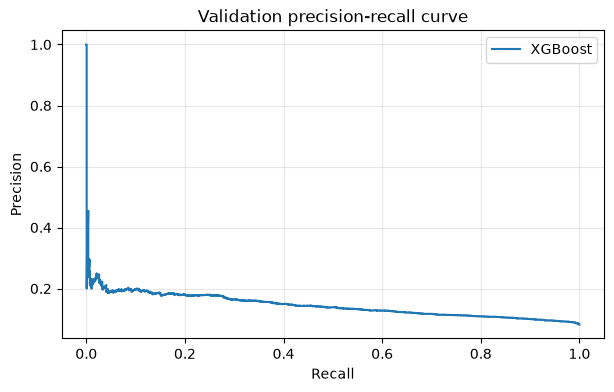

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(valid_recall, valid_precision, label=best_model_name)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation precision-recall curve")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 9. Final evaluation on the untouched test set

This is the first and only use of the test labels for model performance reporting. Keep the selected model and threshold fixed.

In [13]:
test_probability = best_model.predict_proba(X_test_matrix)[:, 1]
test_prediction = (test_probability >= selected_threshold).astype("int8")

final_metrics = {
    "model": best_model_name,
    "threshold_selected_on_validation": selected_threshold,
    "test_ROC_AUC": roc_auc_score(y_test, test_probability),
    "test_PR_AUC": average_precision_score(y_test, test_probability),
    "test_precision": precision_score(y_test, test_prediction, zero_division=0),
    "test_recall": recall_score(y_test, test_prediction, zero_division=0),
    "test_F1": f1_score(y_test, test_prediction, zero_division=0),
    "test_fraud_prevalence": float(y_test.mean())
}
display(pd.DataFrame([final_metrics]).T.rename(columns={0: "value"}))
print(classification_report(y_test, test_prediction, zero_division=0))

,value
model,XGBoost
threshold_selected_on_validation,0.583871
test_ROC_AUC,0.666113
test_PR_AUC,0.143228
test_precision,0.152189
test_recall,0.363636
test_F1,0.214574
test_fraud_prevalence,0.082867


              precision    recall  f1-score   support

           0       0.93      0.82      0.87     13757
           1       0.15      0.36      0.21      1243

    accuracy                           0.78     15000
   macro avg       0.54      0.59      0.54     15000
weighted avg       0.87      0.78      0.82     15000



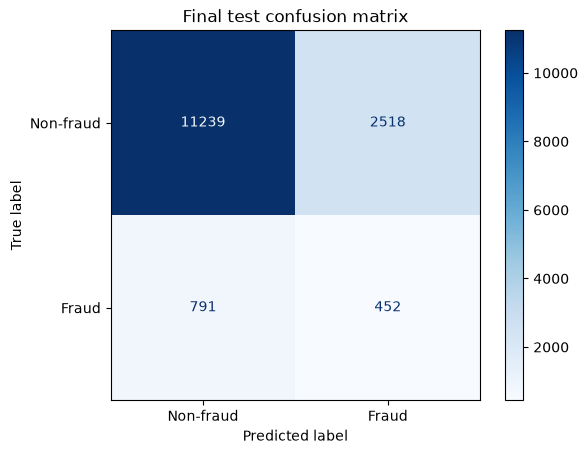

{'true_negative': np.int64(11239), 'false_positive': np.int64(2518), 'false_negative': np.int64(791), 'true_positive': np.int64(452)}
False positives: 2518 | False negatives: 791


In [14]:
cm = confusion_matrix(y_test, test_prediction, labels=[0, 1])
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-fraud", "Fraud"]
).plot(cmap="Blues", values_format="d")
plt.title("Final test confusion matrix")
plt.show()

tn, fp, fn, tp = cm.ravel()
print({"true_negative": tn, "false_positive": fp, "false_negative": fn, "true_positive": tp})
print("False positives:", fp, "| False negatives:", fn)

## 10. Model comparison on validation data

Do not compare models using test scores and then select the winner. The table below is the valid model-selection comparison because all candidates were ranked using validation PR-AUC.

In [15]:
display(validation_scores)
print("Selected model:", best_model_name)
print("Selection metric: validation PR-AUC")

,model,validation_ROC_AUC,validation_PR_AUC
0,XGBoost,0.665822,0.144856
1,Logistic Regression,0.655133,0.141144
2,Random Forest,0.642521,0.127628


Selected model: XGBoost
Selection metric: validation PR-AUC


## 11. Feature importance on validation data

Permutation importance can be computationally expensive. Run it on a bounded validation sample and a small number of repeats. It is a diagnostic, not a causal explanation.

In [16]:
from sklearn.inspection import permutation_importance

importance_sample_size = min(1500, len(X_valid))
X_valid_small = X_valid.iloc[:importance_sample_size]
y_valid_small = y_valid.iloc[:importance_sample_size]

try:
    perm = permutation_importance(
        best_model,
        preprocessor.transform(X_valid_small),
        y_valid_small,
        n_repeats=2,
        random_state=42,
        scoring="average_precision",
        n_jobs=1
    )
    # Encoded-feature names are used because one-hot encoding expands columns.
    try:
        encoded_names = preprocessor.get_feature_names_out()
    except Exception:
        encoded_names = np.array([f"feature_{i}" for i in range(len(perm.importances_mean))])
    importance = pd.Series(perm.importances_mean, index=encoded_names).sort_values(ascending=False).head(20)
    display(importance.to_frame("validation_permutation_importance"))
except Exception as exc:
    print("Permutation importance skipped to conserve resources:", repr(exc))

Permutation importance skipped to conserve resources: InvalidParameterError("The 'X' parameter of permutation_importance must be an array-like. Got <Compressed Sparse Row sparse matrix of dtype 'float64'\n\twith 25176 stored elements and shape (1500, 78)> instead.")


## 12. Memory-safe clustering

Do not densify the full one-hot matrix. This section uses only a small sample and a **MiniBatchKMeans** workflow. Sparse input is retained.

The clustering is exploratory: clusters describe feature similarity, not fraud labels.

In [17]:
CLUSTER_SAMPLE_MAX = 5000
rng = np.random.default_rng(42)
sample_n = min(CLUSTER_SAMPLE_MAX, X_train_matrix.shape[0])
sample_rows = rng.choice(X_train_matrix.shape[0], size=sample_n, replace=False)
X_cluster = X_train_matrix[sample_rows]

cluster_model = MiniBatchKMeans(
    n_clusters=4,
    random_state=42,
    batch_size=256,
    n_init=3,
    max_iter=100
)
cluster_labels = cluster_model.fit_predict(X_cluster)

print("Cluster sample size:", sample_n)
display(pd.Series(cluster_labels, name="cluster").value_counts().sort_index().to_frame("rows"))
print("Reminder: cluster membership is not a fraud decision.")

Cluster sample size: 5000


,rows
cluster,
0,828
1,1479
2,2190
3,503


Reminder: cluster membership is not a fraud decision.


## 13. Memory-safe anomaly detection

Isolation Forest is trained on a small sample. We use the numeric feature subset to keep the feature matrix manageable. The anomaly label is not equivalent to confirmed fraud.

In [18]:
numeric_for_anomaly = numeric_columns[:]
if numeric_for_anomaly:
    anomaly_frame = X_train[numeric_for_anomaly].copy()
    anomaly_frame = anomaly_frame.replace([np.inf, -np.inf], np.nan)
    anomaly_frame = anomaly_frame.fillna(anomaly_frame.median(numeric_only=True))
    anomaly_frame = anomaly_frame.astype("float32")

    anomaly_n = min(5000, len(anomaly_frame))
    anomaly_sample = anomaly_frame.sample(anomaly_n, random_state=42)

    isolation_model = IsolationForest(
        n_estimators=80,
        max_samples=min(256, anomaly_n),
        contamination="auto",
        random_state=42,
        n_jobs=2
    )
    anomaly_result = isolation_model.fit_predict(anomaly_sample)
    anomaly_count = int((anomaly_result == -1).sum())
    print(f"Anomalies detected in sample: {anomaly_count} / {anomaly_n}")
else:
    print("No numeric features available; anomaly detection skipped.")

Anomalies detected in sample: 978 / 5000


## 14. Optional PyTorch experiment — compact numeric-only MLP

This section is optional and intentionally avoids the high-dimensional one-hot matrix that caused the original notebook's MemoryError.

It uses only a limited set of numeric features, a bounded sample, `float32`, and mini-batches. CPU execution is supported. If RAM is low, skip this section.

This experiment is not part of the primary model selection and should not be compared with the main test results unless you build a separate validation protocol.

In [19]:
RUN_PYTORCH_EXPERIMENT = False  # Change to True only when available RAM is sufficient.

if RUN_PYTORCH_EXPERIMENT:
    try:
        import torch
        from torch import nn
        from torch.utils.data import TensorDataset, DataLoader

        torch.set_num_threads(2)
        dl_features = numeric_columns[:20]
        if not dl_features:
            raise ValueError("No numeric predictors for compact MLP.")

        # Bounded row samples; fit imputing/scaling on training rows only.
        from sklearn.impute import SimpleImputer
        from sklearn.preprocessing import StandardScaler

        dl_train = X_train[dl_features].replace([np.inf, -np.inf], np.nan)
        dl_valid = X_valid[dl_features].replace([np.inf, -np.inf], np.nan)

        dl_imputer = SimpleImputer(strategy="median")
        dl_scaler = StandardScaler()

        dl_train_array = dl_imputer.fit_transform(dl_train).astype("float32")
        dl_valid_array = dl_imputer.transform(dl_valid).astype("float32")
        dl_train_array = dl_scaler.fit_transform(dl_train_array).astype("float32")
        dl_valid_array = dl_scaler.transform(dl_valid_array).astype("float32")

        # Bound the experiment to 20,000 training rows for 8 GB systems.
        max_dl_rows = min(20000, len(dl_train_array))
        dl_train_array = dl_train_array[:max_dl_rows]
        dl_y = y_train.iloc[:max_dl_rows].to_numpy(dtype="float32")

        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        print("Device:", device)

        X_tensor = torch.from_numpy(dl_train_array)
        y_tensor = torch.from_numpy(dl_y.reshape(-1, 1))
        loader = DataLoader(
            TensorDataset(X_tensor, y_tensor),
            batch_size=128,
            shuffle=True,
            num_workers=0
        )

        class SmallFraudMLP(nn.Module):
            def __init__(self, n_features):
                super().__init__()
                self.network = nn.Sequential(
                    nn.Linear(n_features, 32),
                    nn.ReLU(),
                    nn.Dropout(0.15),
                    nn.Linear(32, 16),
                    nn.ReLU(),
                    nn.Linear(16, 1)
                )
            def forward(self, x):
                return self.network(x)

        torch.manual_seed(42)
        mlp = SmallFraudMLP(X_tensor.shape[1]).to(device)
        positive_weight = torch.tensor(
            [(dl_y == 0).sum() / max((dl_y == 1).sum(), 1)],
            dtype=torch.float32,
            device=device
        )
        criterion = nn.BCEWithLogitsLoss(pos_weight=positive_weight)
        optimizer = torch.optim.Adam(mlp.parameters(), lr=0.001)

        for epoch in range(5):
            mlp.train()
            epoch_loss = 0.0
            for xb, yb in loader:
                xb, yb = xb.to(device), yb.to(device)
                optimizer.zero_grad(set_to_none=True)
                loss = criterion(mlp(xb), yb)
                loss.backward()
                optimizer.step()
                epoch_loss += loss.item() * len(xb)
            print(f"Epoch {epoch+1}: loss={epoch_loss/len(X_tensor):.4f}")

        del X_tensor, y_tensor, loader
        gc.collect()
    except ImportError:
        print("PyTorch not installed. Install it only if you want this optional experiment.")
    except Exception as exc:
        print("Optional PyTorch experiment skipped:", repr(exc))
else:
    print("Skipped. Set RUN_PYTORCH_EXPERIMENT=True to run the compact numeric-only experiment.")

Skipped. Set RUN_PYTORCH_EXPERIMENT=True to run the compact numeric-only experiment.


## 15. Conditional NLP analysis

Only run text analysis if the dataset contains a genuine text column (for example, a transaction note or customer comment). Do not treat categorical labels as natural-language text. Confirm the text's provenance, consent, language, and whether it was available before the fraud decision.

In [20]:
text_candidates = [
    c for c in data.columns
    if any(term in str(c).lower() for term in ["description", "review", "comment", "message", "reason", "notes", "narrative"])
]
if text_candidates:
    text_column = text_candidates[0]
    print("Candidate text column:", text_column)
    print("Non-empty examples:")
    display(data[text_column].dropna().astype(str).head(5).to_frame())
    print("Before modelling, verify this text is not generated after the transaction outcome.")
else:
    print("No obvious free-text field found. NLP is not applicable based on detected column names.")

No obvious free-text field found. NLP is not applicable based on detected column names.


## 16. Transaction and GTV time series with a backtest

The original notebook extrapolated six months from a trend model without reporting backtest error. This revision first creates a simple time-ordered holdout for monthly totals and compares a naive forecast with a trend baseline.

A small number of monthly observations is not enough for reliable seasonal modelling. Forecasts are exploratory and should not be treated as current business guidance.

,transactions,GTV_AED
timestamp_utc,,
2024-01-01 00:00:00+00:00,8535,1406303.92
2024-02-01 00:00:00+00:00,7796,1229427.47
2024-03-01 00:00:00+00:00,8516,1389463.78
2024-04-01 00:00:00+00:00,7989,1291270.41
2024-05-01 00:00:00+00:00,8447,1435846.72
2024-06-01 00:00:00+00:00,8249,1344279.08
2024-07-01 00:00:00+00:00,8507,1354819.76
2024-08-01 00:00:00+00:00,8419,1358516.33
2024-09-01 00:00:00+00:00,8226,1376191.37


Naive WAPE: 0.0183
Trend WAPE: 0.0211


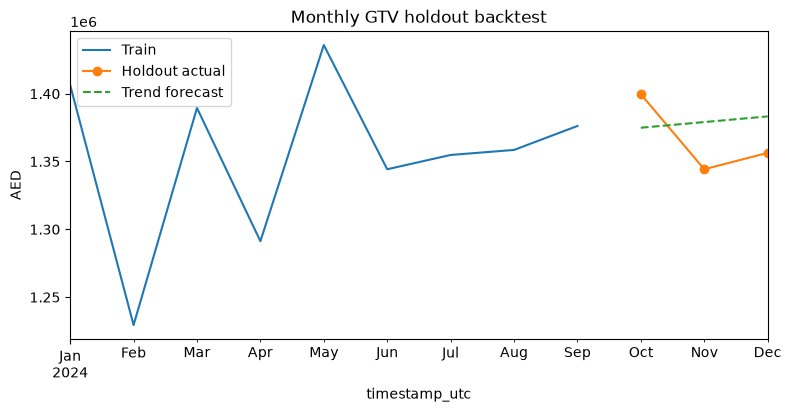

In [21]:
if DATE and AMOUNT:
    monthly = (
        data.dropna(subset=[DATE])
        .set_index(DATE)
        .resample("MS")
        .agg(transactions=(AMOUNT, "size"), GTV_AED=(AMOUNT, "sum"))
        .asfreq("MS")
        .fillna(0)
    )
    display(monthly.tail(12))

    metric_name = "GTV_AED"
    series = monthly[metric_name].astype(float).dropna()

    if len(series) >= 8:
        holdout_size = max(2, min(3, len(series) // 4))
        train_series = series.iloc[:-holdout_size]
        test_series = series.iloc[-holdout_size:]

        naive_forecast = np.repeat(train_series.iloc[-1], len(test_series))
        x_train = np.arange(len(train_series)).reshape(-1, 1)
        x_test = np.arange(len(train_series), len(series)).reshape(-1, 1)

        from sklearn.linear_model import LinearRegression
        trend_model = LinearRegression().fit(x_train, train_series.values)
        trend_forecast = np.maximum(0, trend_model.predict(x_test))

        def wape(actual, predicted):
            denominator = np.abs(actual).sum()
            return np.nan if denominator == 0 else np.abs(actual - predicted).sum() / denominator

        print("Naive WAPE:", round(wape(test_series.values, naive_forecast), 4))
        print("Trend WAPE:", round(wape(test_series.values, trend_forecast), 4))

        plt.figure(figsize=(9, 4))
        train_series.plot(label="Train")
        test_series.plot(label="Holdout actual", marker="o")
        pd.Series(trend_forecast, index=test_series.index).plot(label="Trend forecast", linestyle="--")
        plt.title("Monthly GTV holdout backtest")
        plt.ylabel("AED")
        plt.legend()
        plt.show()
    else:
        print("At least 8 monthly observations are recommended for this simple holdout exercise.")
else:
    print("Forecasting requires both a usable timestamp and transaction amount.")

## 17. Save the model, metrics, and test predictions

The fitted preprocessing pipeline and model are saved together so inference uses the same transformations. Only load model files from trusted sources.

The output folder is created beside the notebook. Test predictions are exported for audit and portfolio review.

In [22]:
OUTPUT_DIR = Path("data_science_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", best_model)
])

# The preprocessor was already fitted on training data. The Pipeline object
# stores that fitted transformer and the fitted estimator.
joblib.dump(final_pipeline, OUTPUT_DIR / "fraud_model_pipeline.joblib")

validation_scores.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)
pd.DataFrame([final_metrics]).to_csv(OUTPUT_DIR / "final_test_metrics.csv", index=False)

prediction_export = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "fraud_probability": test_probability,
    "predicted_label": test_prediction,
    "threshold": selected_threshold
})
prediction_export.to_csv(OUTPUT_DIR / "final_test_predictions.csv", index=False)

metadata = {
    "dataset_file": path.name,
    "dataset_rows": int(len(data)),
    "dataset_columns": int(data.shape[1]),
    "target_column": str(TARGET),
    "date_column": str(DATE),
    "split_strategy": split_strategy,
    "selected_model": best_model_name,
    "threshold_selected_on_validation": selected_threshold,
    "excluded_columns": list(map(str, sorted(exclude_columns))),
    "quarantined_columns": list(map(str, quarantined_columns)),
    "feature_count_after_encoding": int(X_train_matrix.shape[1]),
    "note": "Research/portfolio model; not approved for live payment decisions."
}
(OUTPUT_DIR / "run_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print("Saved outputs to:", OUTPUT_DIR.resolve())
print(sorted(p.name for p in OUTPUT_DIR.iterdir()))

Saved outputs to: C:\Users\IQRA TRADERS\Desktop\desktop\5 project AI UAE road MAP\1.1 Sales ecommerse analysis\data_science_outputs
['final_test_metrics.csv', 'final_test_predictions.csv', 'fraud_model_pipeline.joblib', 'model_comparison.csv', 'run_metadata.json', 'test_predictions.csv', 'validation_model_comparison.csv']


## 18. Optional Streamlit dashboard

This dashboard displays descriptive metrics and saved model results. It does not perform live fraud decisions.

Run the following cell to create the app file. Then launch it from a terminal in the same folder:
```bash
streamlit run fraud_intelligence_dashboard.py
```

In [23]:
dashboard_source = r"""
from pathlib import Path
import pandas as pd
import streamlit as st

st.set_page_config(page_title="UAE E-Commerce Fraud Intelligence", layout="wide")
st.title("UAE E-Commerce Fraud Intelligence")
st.caption("Portfolio research dashboard — not a live payment decision system.")

base = Path(__file__).parent
data_path = base / "uae_ecom_fraud_100k.csv"

if not data_path.exists():
    st.error("Place uae_ecom_fraud_100k.csv beside this dashboard.")
    st.stop()

df = pd.read_csv(data_path, low_memory=False)
amount_col = next((c for c in ["amount_aed", "transaction_amount", "amount"] if c in df.columns), None)
target_col = next((c for c in ["is_fraud", "fraud", "fraud_label"] if c in df.columns), None)

if amount_col:
    df[amount_col] = pd.to_numeric(df[amount_col], errors="coerce")
    a, b, c = st.columns(3)
    a.metric("Transactions", f"{len(df):,}")
    b.metric("GTV (AED)", f"{df[amount_col].sum():,.2f}")
    c.metric("Average transaction", f"{df[amount_col].mean():,.2f}")

if target_col:
    fraud = pd.to_numeric(df[target_col], errors="coerce").fillna(0).eq(1)
    st.metric("Fraud-labelled rate", f"{fraud.mean() * 100:.2f}%")
    st.info("Fraud-labelled value is exposure in this dataset, not confirmed financial loss.")

metrics_path = base / "data_science_outputs" / "final_test_metrics.csv"
if metrics_path.exists():
    st.subheader("Final holdout model metrics")
    st.dataframe(pd.read_csv(metrics_path), use_container_width=True)

comparison_path = base / "data_science_outputs" / "validation_model_comparison.csv"
if comparison_path.exists():
    st.subheader("Validation model comparison")
    st.dataframe(pd.read_csv(comparison_path), use_container_width=True)

st.subheader("Sample records")
st.dataframe(df.head(300), use_container_width=True)
"""
Path("fraud_intelligence_dashboard.py").write_text(dashboard_source, encoding="utf-8")
print("Created fraud_intelligence_dashboard.py")

Created fraud_intelligence_dashboard.py


## 19. Final engineering review and limitations

Before presenting this project, answer the following:

### Data and target
- Is the dataset synthetic or real? What is its provenance?
- What exactly does the fraud label represent?
- Are labels delayed, noisy, or based on rules?

### Leakage and time
- Could any feature have been created after the transaction?
- Does the chronological split reflect the intended real-world prediction scenario?
- Would a later time period provide a stronger external holdout?

### Model performance
- Is PR-AUC materially above the fraud prevalence baseline?
- What is the false-positive burden at the chosen threshold?
- Does recall meet a business requirement?
- Has the threshold been selected without test-set information?

### Production readiness
- Is there a point-in-time feature store or reproducible feature pipeline?
- Are data drift and model drift monitored?
- Are decisions auditable and explainable?
- Is there human review and a process for customer appeals?
- Has the system passed privacy, security, and regulatory review?

**Do not claim this notebook is production-ready.** A portfolio model is not a validated payment risk system.

In [24]:
print("FINAL PROJECT SUMMARY")
print("=" * 55)
print("Dataset:", path.name)
print("Rows:", len(data))
print("Features before encoding:", candidate_features.shape[1])
print("Features after encoding:", X_train_matrix.shape[1])
print("Split:", split_strategy)
print("Selected model:", best_model_name)
print("Validation PR-AUC:", round(float(validation_scores.iloc[0]["validation_PR_AUC"]), 4))
print("Final test PR-AUC:", round(float(final_metrics["test_PR_AUC"]), 4))
print("Final test ROC-AUC:", round(float(final_metrics["test_ROC_AUC"]), 4))
print("Threshold selected on validation:", round(selected_threshold, 5))
print("Final test precision:", round(float(final_metrics["test_precision"]), 4))
print("Final test recall:", round(float(final_metrics["test_recall"]), 4))
print("Final test F1:", round(float(final_metrics["test_F1"]), 4))
print("\nStatus: Research/portfolio workflow. Further validation required.")

FINAL PROJECT SUMMARY
Dataset: uae_ecom_fraud_100k.csv
Rows: 100000
Features before encoding: 19
Features after encoding: 78
Split: Chronological 70/15/15
Selected model: XGBoost
Validation PR-AUC: 0.1449
Final test PR-AUC: 0.1432
Final test ROC-AUC: 0.6661
Threshold selected on validation: 0.58387
Final test precision: 0.1522
Final test recall: 0.3636
Final test F1: 0.2146

Status: Research/portfolio workflow. Further validation required.


## 20. Completion checklist

- [ ] I loaded the dataset and confirmed its source.
- [ ] I validated the fraud target and class balance.
- [ ] I reviewed missing values, duplicates, and data types.
- [ ] I excluded identifiers and quarantined suspicious/post-event fields.
- [ ] I created train, validation, and test partitions.
- [ ] I fitted preprocessing on training data only.
- [ ] I kept one-hot encoded matrices sparse.
- [ ] I compared models using validation PR-AUC.
- [ ] I selected the classification threshold using validation data only.
- [ ] I evaluated the selected model once on the untouched test set.
- [ ] I interpreted false positives and false negatives.
- [ ] I ran clustering only on a bounded sample.
- [ ] I treated anomalies as anomalies, not confirmed fraud.
- [ ] I skipped or ran the optional compact PyTorch experiment responsibly.
- [ ] I saved the model and evaluation artifacts.
- [ ] I documented limitations and production-readiness gaps.

### Suggested execution order

1. Run Sections 0–6 first. Confirm memory usage and split integrity.
2. Run Sections 7–10. Review validation and final test results.
3. Run Sections 11–13 only if memory is available.
4. Skip Section 14 unless you explicitly want the optional PyTorch exercise.
5. Run the remaining sections as needed.

**If Windows reports low memory:** stop the kernel, restart Jupyter, close other applications, and rerun from the top. Do not rerun cells that allocate large matrices repeatedly without restarting.